In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np

In [2]:
# Load World Happiness data (2018)
happiness_df = pd.read_csv("../../data/raw/2018.csv")

# Structural overview
print(f"Dataset shape: {happiness_df.shape}")
print("-" * 50)
happiness_df.info()

Dataset shape: (156, 9)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     155 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


In [3]:
happiness_df.isnull().sum()

Overall rank                    0
Country or region               0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       1
dtype: int64

In [4]:
duplicated_values = happiness_df.duplicated()
duplicated_values.sum()

np.int64(0)

In [5]:
happiness_df[happiness_df['Perceptions of corruption'].isnull()]

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
19,20,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN


In [6]:
display(happiness_df.select_dtypes(include='number').describe().T)

,count,mean,std,min,25%,50%,75%,max
Overall rank,156.0,78.500000,45.177428,1.000,39.75000,78.5000,117.25000,156.000
Score,156.0,5.375917,1.119506,2.905,4.45375,5.3780,6.16850,7.632
GDP per capita,156.0,0.891449,0.391921,0.000,0.61625,0.9495,1.19775,2.096
Social support,156.0,1.213237,0.302372,0.000,1.06675,1.2550,1.46300,1.644
Healthy life expectancy,156.0,0.597346,0.247579,0.000,0.42225,0.6440,0.77725,1.030
Freedom to make life choices,156.0,0.454506,0.162424,0.000,0.35600,0.4870,0.57850,0.724
Generosity,156.0,0.181006,0.098471,0.000,0.10950,0.1740,0.23900,0.598
Perceptions of corruption,155.0,0.112000,0.096492,0.000,0.05100,0.0820,0.13700,0.457


In [7]:
# 1. Auto-detect numeric columns
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

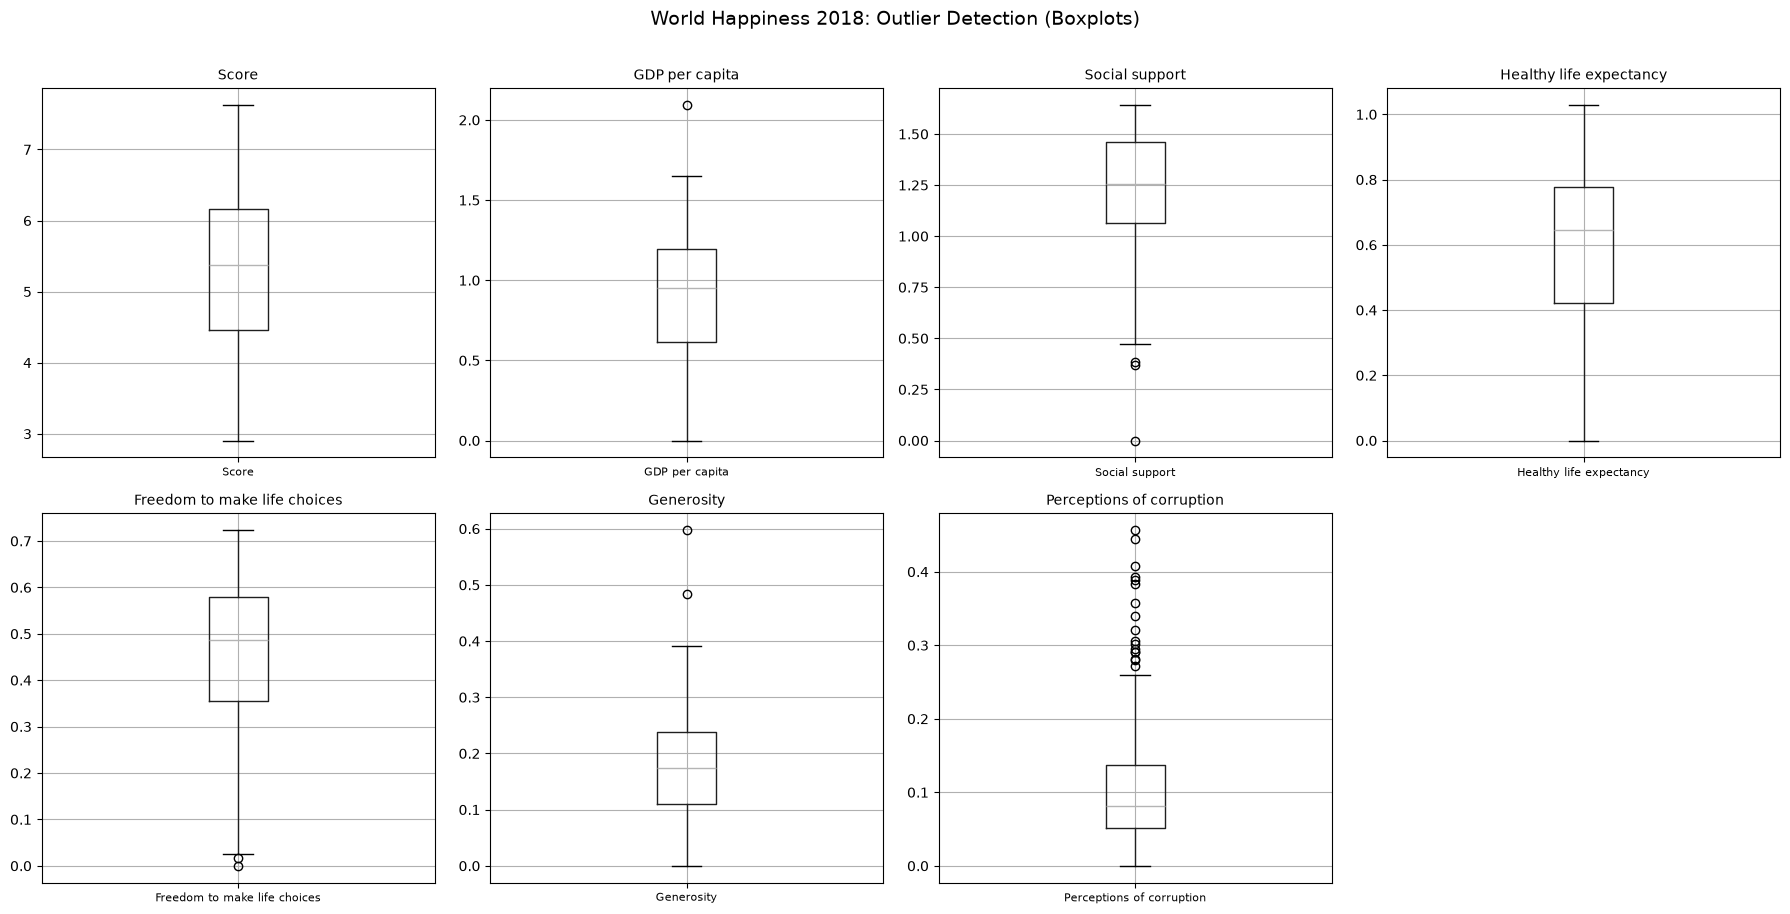

In [8]:
import math



# 🛑 Drop useless columns for 2018 (Rank is the only one to drop here)
cols_to_drop = [
    'Overall rank', 'Happiness.Rank', 'Happiness Rank', 
    'Whisker.high', 'Whisker.low',
    'Lower Confidence Interval', 'Upper Confidence Interval',
    'Lower confidence interval', 'Upper confidence interval',
    'Year'
]
numeric_cols = [c for c in numeric_cols if c not in cols_to_drop]
# Calculate grid size
n = len(numeric_cols)  # n = 7
ncols = 4
nrows = math.ceil(n / ncols)

# Create the figure and axes grid
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
axes = axes.flatten()

# Plot a boxplot for each numeric column
for i, col in enumerate(numeric_cols):
    happiness_df.boxplot(column=col, ax=axes[i], vert=True)
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis="x", labelsize=8)

# Hide ONLY the unused axes
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("World Happiness 2018: Outlier Detection (Boxplots)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [9]:


def get_outliers(df, column_name):
    # 1. Calculate the first quartile (25%) and third quartile (75%)
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    
    # 2. Calculate the Interquartile Range (IQR)
    IQR = Q3 - Q1
    
    # 3. Calculate the bounds (whiskers)
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # 4. Filter the countries that fall outside these bounds
    outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
    
    # 5. Sort by the column value for easy reading
    outliers = outliers[['Country or region', 'Score', column_name]].sort_values(by=column_name)
    
    print(f"--- Outliers for {column_name} (2018) ---")
    print(f"Lower Bound: {lower_bound:.2f} | Upper Bound: {upper_bound:.2f}")
    print(f"Total outliers found: {len(outliers)}")
    print("-" * 55)
    print(outliers.to_string(index=False))

# Ejecutar la función para 'Social support' en 2018
get_outliers(happiness_df, 'Social support')

--- Outliers for Social support (2018) ---
Lower Bound: 0.47 | Upper Bound: 2.06
Total outliers found: 3
-------------------------------------------------------
       Country or region  Score  Social support
Central African Republic  3.083           0.000
                   Benin  4.141           0.372
                   Syria  3.462           0.382


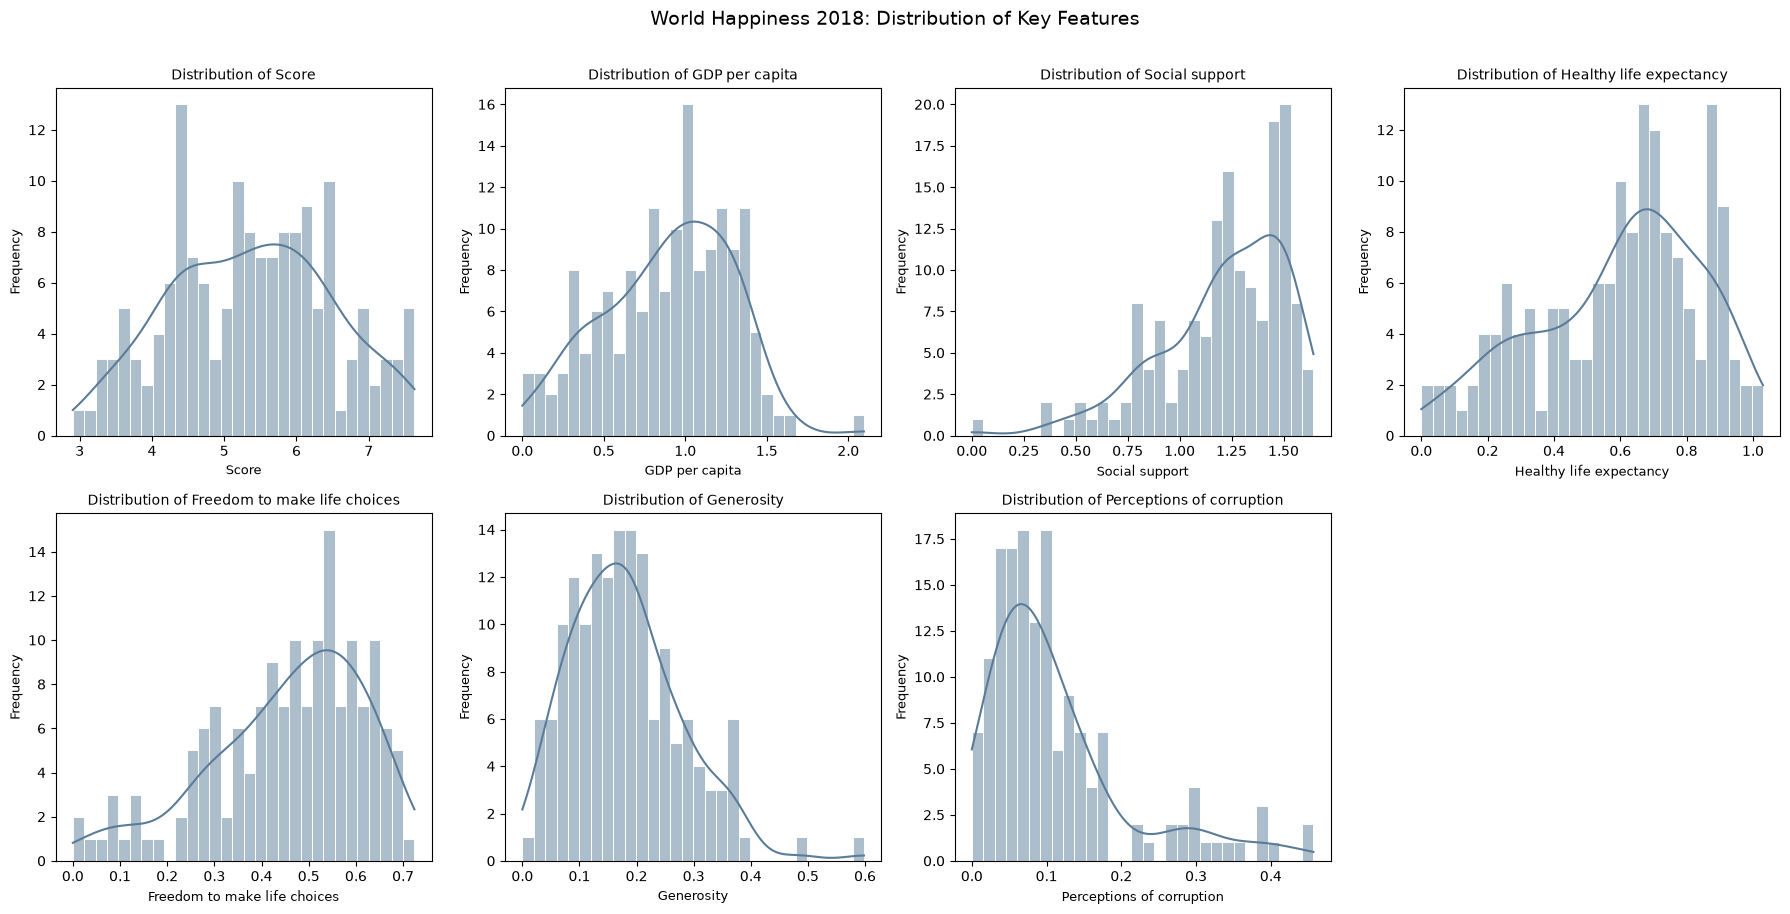

In [10]:
# 2. Drop useless columns specific to 2018 (Only Rank needs to be dropped)
cols_to_exclude = [
    'Overall rank', 'Happiness.Rank', 'Happiness Rank', 
    'Whisker.high', 'Whisker.low',
    'Lower Confidence Interval', 'Upper Confidence Interval',
    'Lower confidence interval', 'Upper confidence interval',
    'Year'
]
clean_cols = [c for c in numeric_cols if c not in cols_to_exclude]

# 3. Calculate grid size
n = len(clean_cols) # n = 7
ncols = 4
nrows = math.ceil(n / ncols)

# 4. Create figure
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
axes = axes.flatten()

# 5. Plot distributions
for i, feature in enumerate(clean_cols):
    sns.histplot(
        happiness_df[feature].dropna(),
        bins=30,
        kde=True,
        ax=axes[i],
        color="#5b7c99",
        edgecolor="white"
    )
    axes[i].set_title(f"Distribution of {feature}", fontsize=10)
    axes[i].set_xlabel(feature, fontsize=9)
    axes[i].set_ylabel("Frequency", fontsize=9)

# 6. Hide unused subplots
for ax in axes[n:]:
    ax.set_visible(False)

# 7. Update title for 2018
fig.suptitle("World Happiness 2018: Distribution of Key Features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

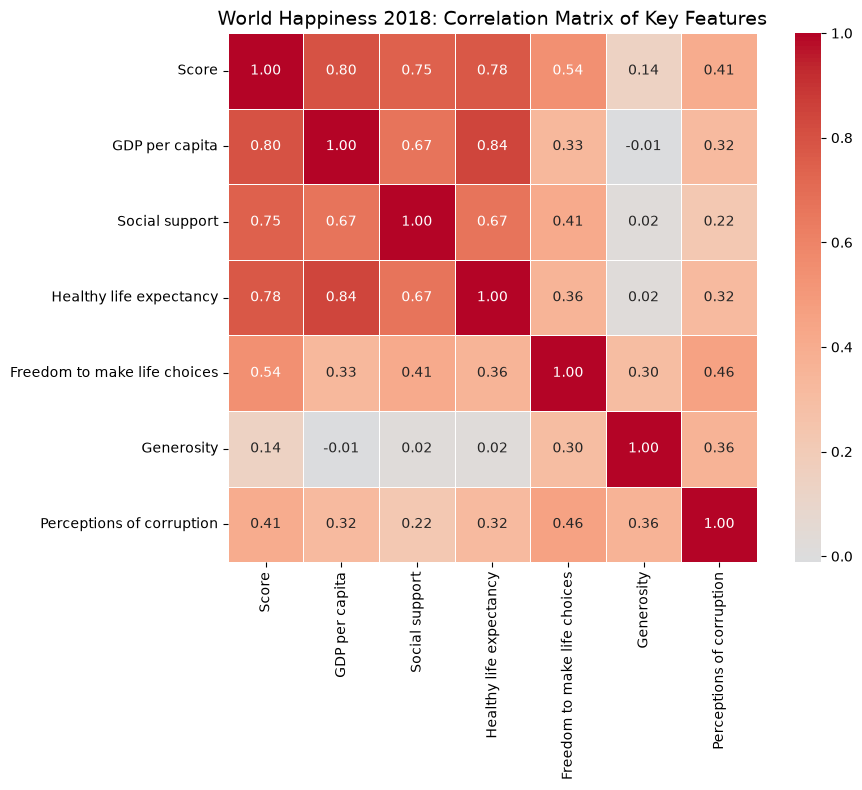

In [11]:
# 2. Drop useless columns SPECIFIC TO 2018
cols_to_exclude = [
    'Overall rank', 
    'Happiness.Rank', 'Happiness Rank', 
    'Whisker.high', 'Whisker.low',
    'Lower Confidence Interval', 'Upper Confidence Interval',
    'Lower confidence interval', 'Upper confidence interval',
    'Year'
]
clean_cols = [c for c in numeric_cols if c not in cols_to_exclude]

# 3. Calculate correlation matrix
corr = happiness_df[clean_cols].corr()

# 4. Plot the full square heatmap
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr, 
    annot=True,         # Show numbers inside the squares
    fmt=".2f",          # 2 decimal places
    cmap="coolwarm",    # Blue to Red colors
    center=0,           # White is exactly 0
    ax=ax, 
    square=True,        # Make the squares perfectly square
    linewidths=0.5      # Small lines between squares
)

# Update the title for 2018
ax.set_title("World Happiness 2018: Correlation Matrix of Key Features", fontsize=14)
plt.tight_layout()
plt.show()